# Assignment #2

# 1. Random Variables (20 pts)

*Note that all proofs must be done using Latex in the corresponding cell block.

**1.1** Prove that $E[aX + b] = aE[X] + b$

$$
\begin{aligned}
E[aX+b]
&= \int_{-\infty}^{\infty}(ax+b)f_X(x)\,dx\\
&= a\int_{-\infty}^{\infty}xf_X(x)\,dx
+b\int_{-\infty}^{\infty}f_X(x)\,dx\\
&= aE[X]+b
\end{aligned}
$$

**1.2** Prove that $Var(X) = E[X^2] - E[X]^2$.

$$
\begin{aligned}
Var(X)
&= E[(X-E[X])^2]\\
&= E[X^2-2XE[X]+(E[X])^2]\\
&= E[X^2]-2E[X]E[X]+(E[X])^2\\
&= E[X^2]-(E[X])^2
\end{aligned}
$$

**1.3** Prove that $Var(X+Y) = Var(X) + Var(Y) + 2Cov(X,Y)$

$$
\begin{aligned}
Var(X+Y)
&= E[(X+Y)^2]-(E[X+Y])^2\\
&= E[X^2+2XY+Y^2]-(E[X]+E[Y])^2\\
&= E[X^2]+2E[XY]+E[Y^2]\\
&\quad -(E[X])^2-2E[X]E[Y]-(E[Y])^2\\
&= [E[X^2]-(E[X])^2]\\
&\quad +[E[Y^2]-(E[Y])^2]\\
&\quad +2[E[XY]-E[X]E[Y]]\\
&= Var(X)+Var(Y)+2Cov(X,Y)
\end{aligned}
$$

**1.4** Given the probability density function of the uniform distribution:

$$
f_X = 
\begin{cases}
\frac{1}{b-a} & a \le x \le b, \\
0 & \text{for}\;x \lt a\;\text{or}\;x \gt b.
\end{cases}$$

Prove that $E[X] = \frac{a+b}{2}$ and $Var(X) = \frac{(b-a)^2}{12}$.

$$
\begin{aligned}
E[X]
&= \int_a^b xf_X(x)\,dx\\
&= \int_a^b x\frac{1}{b-a}\,dx\\
&= \frac{1}{b-a}\left[\frac{x^2}{2}\right]_a^b\\
&= \frac{b^2-a^2}{2(b-a)}\\
&= \frac{(b-a)(a+b)}{2(b-a)}\\
&= \frac{a+b}{2}
\end{aligned}
$$

# 2. Sentinel-2 data over Durham (20 points)

The objective of this problem is to learn how to download, process, and plot spatial data. More specifically, we are going to use data from the version 2.0 of the harmonized-landsat-sentinel-2 (HLS, https://lpdaac.usgs.gov/data/get-started-data/collection-overview/missions/harmonized-landsat-sentinel-2-hls-overview/
) dataset. Begin by opening an account on earthdata.nasa.gov. Then proceed to find and download HLS data to your Docker container for Durham, NC on 09/10/2021. More specifically, the desired bounding box is between longitudes -79.0 and -78.8 and latitudes 35.90 and 36.10. You will need to download a larger region and then subset it on the docker container. You will want to first reproject all your downloaded files to a Plate Carree projection (i.e., regular lat/lon grid) at a 1 arcsec spatial resolution. Proceed to then create a RGB plot using the corresponding Sentinel-2 bands. Converting the radiances "felt" by the satellite to RGB values is not trivial but we will keep it simple; for this problem simply normalize each corresponding band to 0-1 or 0-255 (either will work). Once this is complete, create a map of NDVI (https://gisgeography.com/ndvi-normalized-difference-vegetation-index/) as well.


Valid pixel coverage: 100.0 %


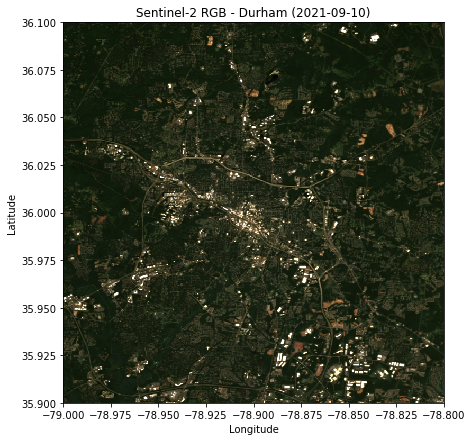

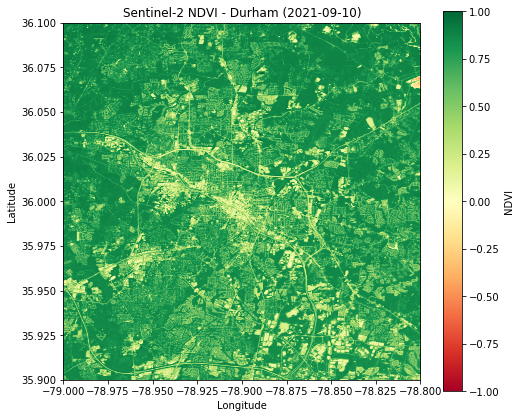

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import reproject, Resampling
from rasterio.transform import from_origin
from pathlib import Path

# Durham bounding box
xmin, xmax = -79.0, -78.8
ymin, ymax = 35.90, 36.10

res = 1 / 3600
width = round((xmax - xmin) / res)
height = round((ymax - ymin) / res)

transform = from_origin(xmin, ymax, res, res)

# Read and reproject bands
def read_band(band):
    file = list(Path(".").glob(f"*T17SPV*.{band}.tif"))[0]
    data = np.full((height, width), np.nan, dtype=np.float32)

    with rasterio.open(file) as src:
        reproject(
            source=rasterio.band(src, 1),
            destination=data,
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=transform,
            dst_crs="EPSG:4326",
            dst_nodata=np.nan,
            resampling=Resampling.bilinear
        )

    return data * 0.0001

red = read_band("B04")
green = read_band("B03")
blue = read_band("B02")
nir = read_band("B8A")

# Check valid-data coverage
valid = (
    np.isfinite(red) &
    np.isfinite(green) &
    np.isfinite(blue) &
    np.isfinite(nir)
)

print("Valid pixel coverage:", round(valid.mean() * 100, 2), "%")

# RGB
rgb = np.stack([red, green, blue], axis=-1)
rgb = np.clip(rgb / 0.3, 0, 1)

extent = [xmin, xmax, ymin, ymax]

plt.figure(figsize=(8, 7))
plt.imshow(rgb, extent=extent, origin="upper")
plt.title("Sentinel-2 RGB - Durham (2021-09-10)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

# NDVI
with np.errstate(divide="ignore", invalid="ignore"):
    ndvi = (nir - red) / (nir + red)

ndvi[~valid] = np.nan
ndvi[~np.isfinite(ndvi)] = np.nan

plt.figure(figsize=(8, 7))
plt.imshow(ndvi, extent=extent, origin="upper",
           cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(label="NDVI")
plt.title("Sentinel-2 NDVI - Durham (2021-09-10)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

# 3. Calculating the correct spatial mean (20 pts)

A simple spatial mean of a regular lat/long grid (Plate Carree) can lead to large discrepancies in the estimated spatial mean. To assess this impact, we are going to use the variable `t2m` in the annual ERA-Interim database (`/data/era-interim/era_interim_monthly_197901_201512_upscaled.nc_ann`). Start by assembling an array of actual area per pixel and then compute for each year the area weighted mean. Then compare the resulting time series to that resulting from using the equally weighted spatial mean (i.e., naive approach). Provide an explanation of your results.

<xarray.Dataset>
Dimensions:           (bnds: 2, lat: 180, lon: 288, time: 37)
Coordinates:
  * time              (time) datetime64[ns] 1979-07-01T06:00:00 ... 2015-07-01T06:00:00
  * lon               (lon) float32 0.625 1.8728299 ... 357.50433 358.75217
  * lat               (lat) float32 -89.5 -88.5 -87.5 -86.5 ... 87.5 88.5 89.5
Dimensions without coordinates: bnds
Data variables:
    time_bnds         (time, bnds) datetime64[ns] ...
    albedo_sfc        (time, lat, lon) float32 ...
    blh               (time, lat, lon) float32 ...
    cape              (time, lat, lon) float32 ...
    d2m               (time, lat, lon) float32 ...
    evap              (time, lat, lon) float32 ...
    evap_snow         (time, lat, lon) float32 ...
    height_sfc        (lat, lon) float32 ...
    hi_cld            (time, lat, lon) float32 ...
    land_mask         (lat, lon) float32 ...
    lhflx             (time, lat, lon) float32 ...
    lo_cld            (time, lat, lon) float32 ...
    lwflx

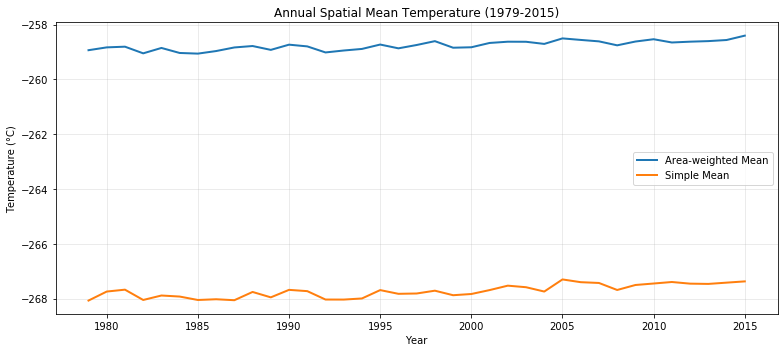

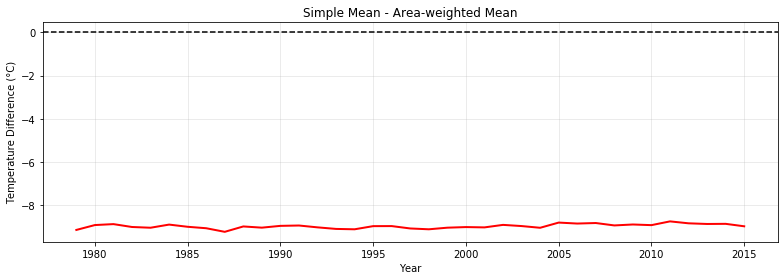

Average difference: -8.964454587800379 °C


In [17]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# 1. Read ERA-Interim data
file = "/data/era-interim/era_interim_monthly_197901_201512_upscaled.nc_ann"
ds = xr.open_dataset(file)

print(ds)

t2m = ds["t2m"]

# 2. Get latitude and longitude
lat_name = "latitude" if "latitude" in t2m.dims else "lat"
lon_name = "longitude" if "longitude" in t2m.dims else "lon"

lat = t2m[lat_name].values
lon = t2m[lon_name].values

# 3. Calculate actual area per grid cell
R = 6371000  # Earth radius (m)

lat_edges = np.empty(len(lat) + 1)
lat_edges[1:-1] = (lat[:-1] + lat[1:]) / 2
lat_edges[0] = lat[0] - (lat[1] - lat[0]) / 2
lat_edges[-1] = lat[-1] + (lat[-1] - lat[-2]) / 2
lat_edges = np.clip(lat_edges, -90, 90)

dlon = np.deg2rad(abs(np.mean(np.diff(lon))))

area_lat = R**2 * dlon * np.abs(
    np.sin(np.deg2rad(lat_edges[1:])) -
    np.sin(np.deg2rad(lat_edges[:-1]))
)

# 2D area array (m² per pixel)
area = xr.DataArray(
    np.broadcast_to(
        area_lat[:, None],
        (len(lat), len(lon))
    ),
    dims=[lat_name, lon_name],
    coords={lat_name: lat, lon_name: lon}
)

# 4. Area-weighted spatial mean
valid_area = area.where(t2m.notnull())

weighted_mean = (t2m * area).sum(
    dim=[lat_name, lon_name],
    skipna=True
) / valid_area.sum(
    dim=[lat_name, lon_name],
    skipna=True
)

# 5. Equally weighted spatial mean
simple_mean = t2m.mean(
    dim=[lat_name, lon_name],
    skipna=True
)

# 6. Get annual time series
if "time" in t2m.dims:
    years = t2m.time.dt.year.values
else:
    years = np.arange(1979, 1979 + len(weighted_mean))

# Convert from Kelvin to Celsius
weighted_mean = weighted_mean - 273.15
simple_mean = simple_mean - 273.15

# 7. Compare the two methods
plt.figure(figsize=(11, 5))

plt.plot(years, weighted_mean,
         label="Area-weighted Mean", linewidth=2)

plt.plot(years, simple_mean,
         label="Simple Mean", linewidth=2)

plt.xlabel("Year")
plt.ylabel("Temperature (°C)")
plt.title("Annual Spatial Mean Temperature (1979-2015)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# 8. Plot difference
difference = simple_mean - weighted_mean

plt.figure(figsize=(11, 4))
plt.plot(years, difference, color="red", linewidth=2)
plt.axhline(0, color="black", linestyle="--")

plt.xlabel("Year")
plt.ylabel("Temperature Difference (°C)")
plt.title("Simple Mean - Area-weighted Mean")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Average difference:", float(difference.mean()), "°C")


# 4. North Carolina county level elevation statistics (20 pts)

Given the shapefile of county boundaries (`/data/HW/HW2/NCDOT_County_Boundaries.shp`) and the USGS National Elevation Dataset (`/data/NED/NED.vrt`), compute the following statistics: the spatial mean, the spatial standard deviation, and the coefficient of variation of elevation per NC county. Once this database is assembled, use bar plots to show the results across all the counties (one bar plot per statistic). Explain the results. To make things simple you will want to use the Plate Carree projection (regular lat/lon grid) at a 0.01 by 0.01 arcdegree spatial resolution.

In [25]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import matplotlib.pyplot as plt

from rasterio.transform import from_origin
from rasterio.features import geometry_mask
from rasterio.enums import Resampling
from rasterio.vrt import WarpedVRT

# --------------------------------------------------
# 1. Read NC county boundaries
# --------------------------------------------------
shp_file = "/data/HW/HW2/NCDOT_County_Boundaries.shp"
dem_file = "/data/NED/NED.vrt"

counties = gpd.read_file(shp_file)
counties = counties.to_crs("EPSG:4326")

print("Number of counties:", len(counties))

name_col = "CountyName"

# --------------------------------------------------
# 2. Create Plate Carree grid (0.01 degree)
# --------------------------------------------------
xmin, ymin, xmax, ymax = counties.total_bounds

res = 0.01
width = int(np.ceil((xmax - xmin) / res))
height = int(np.ceil((ymax - ymin) / res))

transform = from_origin(xmin, ymax, res, res)

print("Grid size:", width, height)

# --------------------------------------------------
# 3. Read DEM directly on a 0.01-degree grid

from rasterio.transform import from_origin
from rasterio.enums import Resampling

res = 0.01

with rasterio.open("/data/NED/NED.vrt") as src:

    # Define exact grid boundaries
    xmin, ymin, xmax, ymax = counties.total_bounds

    width = int(np.ceil((xmax - xmin) / res))
    height = int(np.ceil((ymax - ymin) / res))

    transform = from_origin(xmin, ymax, res, res)

    # Read using the actual pixel coordinates of the target grid
    rows = np.arange(height)
    cols = np.arange(width)

    lons = xmin + (cols + 0.5) * res
    lats = ymax - (rows + 0.5) * res

    lon_grid, lat_grid = np.meshgrid(lons, lats)

    # Convert longitude and latitude to DEM pixel indices
    source_rows, source_cols = rasterio.transform.rowcol(
        src.transform,
        lon_grid.ravel(),
        lat_grid.ravel()
    )

    source_rows = np.asarray(source_rows)
    source_cols = np.asarray(source_cols)

    # Read a source window covering the target grid
    r0, r1 = source_rows.min(), source_rows.max() + 1
    c0, c1 = source_cols.min(), source_cols.max() + 1

    window = rasterio.windows.Window(
        c0, r0, c1 - c0, r1 - r0
    )

    source = src.read(1, window=window, masked=True)

    # Sample source data at target grid-cell centers
    rr = source_rows - r0
    cc = source_cols - c0

    dem = np.asarray(
        source[rr, cc].filled(np.nan),
        dtype=np.float32
    ).reshape(height, width)

print("Valid DEM pixels:", np.isfinite(dem).sum())
print("DEM minimum:", np.nanmin(dem))
print("DEM maximum:", np.nanmax(dem))
# --------------------------------------------------
# 4. Calculate statistics for each county
# --------------------------------------------------
results = []

for _, county in counties.iterrows():

    mask = geometry_mask(
        [county.geometry],
        out_shape=dem.shape,
        transform=transform,
        invert=True
    )

    values = dem[mask & np.isfinite(dem)]

    if len(values) == 0:
        continue

    mean = np.mean(values)
    std = np.std(values)

    if mean != 0:
        cv = std / mean
    else:
        cv = np.nan

    results.append({
        "County": county[name_col],
        "Mean": mean,
        "Std": std,
        "CV": cv
    })

# --------------------------------------------------
# 5. Create results table
# --------------------------------------------------
df = pd.DataFrame(
    results,
    columns=["County", "Mean", "Std", "CV"]
)

df = df.sort_values("County").reset_index(drop=True)

print(df.head())
print("Counties calculated:", len(df))

if len(df) == 0:
    raise ValueError("No county statistics were calculated.")

# --------------------------------------------------
# 6. Plot mean elevation
# --------------------------------------------------
plt.figure(figsize=(20, 6))

plt.bar(df["County"], df["Mean"])

plt.title("Mean Elevation by NC County")
plt.xlabel("County")
plt.ylabel("Mean Elevation (m)")
plt.xticks(rotation=90, fontsize=7)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 7. Plot standard deviation
# --------------------------------------------------
plt.figure(figsize=(20, 6))

plt.bar(df["County"], df["Std"], color="orange")

plt.title("Elevation Standard Deviation by NC County")
plt.xlabel("County")
plt.ylabel("Standard Deviation (m)")
plt.xticks(rotation=90, fontsize=7)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 8. Plot coefficient of variation
# --------------------------------------------------
plt.figure(figsize=(20, 6))

plt.bar(df["County"], df["CV"], color="green")

plt.title("Elevation Coefficient of Variation by NC County")
plt.xlabel("County")
plt.ylabel("Coefficient of Variation")
plt.xticks(rotation=90, fontsize=7)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 9. Save results
# --------------------------------------------------
df.to_csv(
    "NC_county_elevation_statistics.csv",
    index=False
)

print("Done!")

Number of counties: 100
Grid size: 275 887


IndexError: index 0 is out of bounds for axis 0 with size 0

# 5. Flying from LAX to LHR (20 pts)

Create a rotating globe that tracks an actual flight from Los Angeles to London that happened between 2020/09/17-2020/09/18. The file `/data/HW/HW2/lax2lhr_20200917.pck` contains the GPS location of the flight at discrete timestamps during the flight. The goal here is to create a movie where each frame builds on the previous one to build out the time evolving flight path. The flight path should be drawn as lines joined at nodes. Each frame update should correspond to a new timestamp. Furthermore, for each timestamp, the globe should be centered on the timestamp's corresponding longitude. Finally, add the time evolving rainfall maps that was forecasted during each timestamp. For this part, you will use a 9/17/2020 forecast from NOAA's Global Forecasting System (GFS) which you can find in  `/data/HW/HW2/gfs20200917_gfs_0p25_1hr_00z.nc`. The variable of interest in that dataset will be `pratesfc`. Note that there are many ways to do this problem so feel free to explore your own ideas. However, for reference, below is an example of what the last frame might look like. We look forward to seeing what you come up with! 
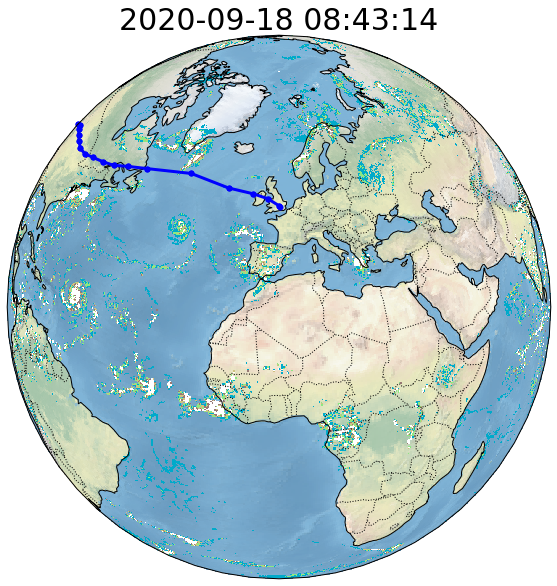

In [29]:
import numpy as np
import pandas as pd
import xarray as xr
import pickle
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import cartopy.crs as ccrs
from IPython.display import display, Video, Image

# 1. Read flight GPS data
with open("/data/HW/HW2/lax2lhr_20200917.pck", "rb") as f:
    flight = pickle.load(f)

lats = np.asarray(flight["lat"])
lons = np.asarray(flight["lon"])
dates = pd.to_datetime(flight["date"])

# Sort by time
order = np.argsort(dates)
lats = lats[order]
lons = lons[order]
dates = dates[order]

# 2. Read GFS precipitation
ds = xr.open_dataset(
    "/data/HW/HW2/gfs20200917_gfs_0p25_1hr_00z.nc"
)

rain = ds["pratesfc"]
gfs_times = pd.to_datetime(ds["time"].values)

# Reduce resolution to speed up animation
rain_lat = ds["lat"].values[::4]
rain_lon = ds["lon"].values[::4]

# 3. Create the figure
fig = plt.figure(figsize=(10, 8))

def update(i):
    fig.clear()

    # Rotate globe according to flight longitude
    ax = fig.add_subplot(
        111,
        projection=ccrs.Orthographic(
            central_longitude=float(lons[i]),
            central_latitude=30
        )
    )

    ax.set_global()
    ax.stock_img()

    # Find nearest GFS forecast time
    idx = np.argmin(
        np.abs(gfs_times - dates[i])
    )

    # Precipitation: kg/m2/s -> mm/hour
    precip = rain.isel(time=int(idx)).values[::4, ::4] * 3600
    precip = np.ma.masked_less(precip, 0.2)

    # Plot precipitation
    ax.pcolormesh(
        rain_lon,
        rain_lat,
        precip,
        transform=ccrs.PlateCarree(),
        cmap="Blues",
        vmin=0.2,
        vmax=10,
        alpha=0.75,
        shading="auto"
    )

    # Draw flight path up to current time
    ax.plot(
        lons[:i+1],
        lats[:i+1],
        color="blue",
        linewidth=2,
        marker="o",
        markersize=3,
        transform=ccrs.Geodetic()
    )

    # Current aircraft position
    ax.plot(
        lons[i],
        lats[i],
        "ro",
        markersize=7,
        transform=ccrs.PlateCarree()
    )

    # Title
    ax.set_title(
        dates[i].strftime("%Y-%m-%d %H:%M:%S"),
        fontsize=18
    )

    return []

# 4. Create animation
ani = animation.FuncAnimation(
    fig,
    update,
    frames=len(lats),
    interval=300,
    blit=False
)

# 5. Save animation
if animation.FFMpegWriter.isAvailable():
    ani.save("LAX_to_LHR.mp4", writer="ffmpeg", fps=3)
    plt.close(fig)
    display(Video("LAX_to_LHR.mp4", embed=True))
else:
    ani.save("LAX_to_LHR.gif", writer="pillow", fps=3)
    plt.close(fig)
    display(Image(filename="LAX_to_LHR.gif"))

print("Animation completed!")
print("Total frames:", len(lats))

Animation completed!
Total frames: 20
